<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/08_%E9%9B%86%E6%88%90%E5%AD%B8%E7%BF%92/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08. 集成學習 (Ensemble Learning)

集成學習的核心哲學是「三個臭皮匠，勝過諸葛亮」。本範例讀取「金融詐欺偵測資料集」示範：
1. **單一弱決策樹** vs **隨機森林 (Bagging)** vs **梯度提升樹 (Boosting)**。
2. 使用 Seaborn 繪製各演算法的準確率與特徵重要性 (Feature Importance) 長條圖。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 讀取金融詐欺偵測資料集
df = pd.read_csv('金融詐欺偵測資料集.csv')
features = ['單筆金額_萬元', '夜間登入次數', '跨國IP風險值', '設備更換頻率']
X = df[features]
y = (df['是否異常詐欺'] == '異常詐欺').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 1. 訓練三種模型
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=42).fit(X_train, y_train)
gb = GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=42).fit(X_train, y_train)

acc_tree = tree.score(X_test, y_test)
acc_rf = rf.score(X_test, y_test)
acc_gb = gb.score(X_test, y_test)

print("=== 模型測試準確率比較 ===")
print(f"單一淺層決策樹 (Single Tree):     {acc_tree:.1%}")
print(f"隨機森林 (Random Forest, Bagging): {acc_rf:.1%}")
print(f"梯度提升 (Gradient Boost, Boost):  {acc_gb:.1%}")


=== 模型測試準確率比較 ===
單一淺層決策樹 (Single Tree):     63.3%
隨機森林 (Random Forest, Bagging): 64.4%
梯度提升 (Gradient Boost, Boost):  64.4%


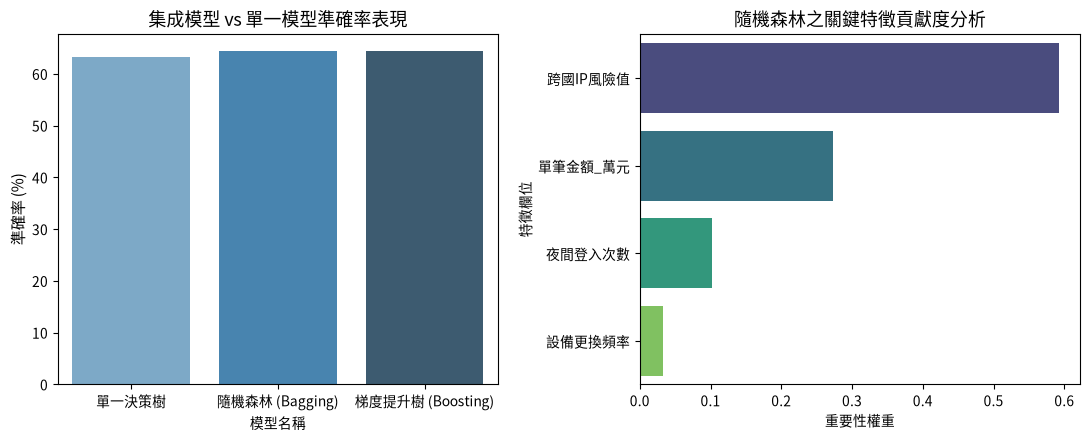

💡 觀念總結：集成學習透過降低變異數 (Bagging) 或降低偏差 (Boosting)，展現強悍的抗噪與泛化優勢！


In [4]:
# 2. 繪製準確率與隨機森林特徵重要性長條圖
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# 子圖 1: 準確率比較
perf_df = pd.DataFrame({
    '模型名稱': ['單一決策樹', '隨機森林 (Bagging)', '梯度提升樹 (Boosting)'],
    '測試準確率': [acc_tree * 100, acc_rf * 100, acc_gb * 100]
})
sns.barplot(ax=axes[0], data=perf_df, x='模型名稱', y='測試準確率', hue='模型名稱', palette='Blues_d', legend=False)
axes[0].set_title('集成模型 vs 單一模型準確率表現', fontsize=13)
axes[0].set_ylabel('準確率 (%)', fontsize=11)

# 子圖 2: 隨機森林特徵重要性
feat_df = pd.DataFrame({
    '特徵欄位': features,
    '重要性權重': rf.feature_importances_
}).sort_values('重要性權重', ascending=False)
sns.barplot(ax=axes[1], data=feat_df, x='重要性權重', y='特徵欄位', hue='特徵欄位', palette='viridis', legend=False)
axes[1].set_title('隨機森林之關鍵特徵貢獻度分析', fontsize=13)

plt.tight_layout()
plt.show()

print("💡 觀念總結：集成學習透過降低變異數 (Bagging) 或降低偏差 (Boosting)，展現強悍的抗噪與泛化優勢！")
